# 02 · Your first events in Python

**Time:** 40 minutes · **Needs:** X-SCAPE (the production container, the Mac wheel or a source build) · **Data:** none: the notebook makes its own (about 10 MB in `out/`)

Tutorial 01 read files that someone else made. Here you make your own: three O+O collisions
at 200 GeV, each with a hard scattering, run through the whole X-SCAPE chain from a Python
loop with the Pythonic interface of PyJetscape. Along the way:
- what each stage of the chain does, and what it hands to the next;
- the hadrons it produces, as numpy and awkward arrays, with a first $dN/d\eta$ and $p_T$
  spectrum;
- one physics setting changed, the shear viscosity of the fluid, and its effect on the
  *same* three collisions.

The two runs take about a minute on a GPU (MUSIC on the CPU is several times slower).

Reference pages: [Your first event](https://jhputschke.github.io/js-contrib/run/first-event/),
[The Pythonic interface](https://jhputschke.github.io/js-contrib/python/pythonic/), [The physics](https://jhputschke.github.io/js-contrib/about/physics/).

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/).
import os, sys
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
env = te.setup()

tutorials v1.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


In [2]:
ok, missing = te.meets(['xscape'], env.caps)
assert ok, f"this tutorial needs {missing}: see 01_check_setup.ipynb"

## 1. The chain of stages

An X-SCAPE run is a list of *modules*, one per stage of a collision, called in order for
every event. Which modules run, and with which settings, is set by two XML files: the
**main XML** (`config/jetscape_main.xml`), which holds a default for every setting, and the
**user XML**, which names the modules of this run and changes what differs from the
defaults. We start from the user XML of the example `pythonic/oo_workflow.py` (its
[page](https://jhputschke.github.io/js-contrib/run/first-event/)). It runs the physics settings of the O+O production.

From the first stage to the last:

1. **Initial state** (3dMCGlauber). The nucleons of the two oxygen nuclei are placed in
   the transverse plane and collide where they overlap. Each nucleon–nucleon collision can
   stretch a QCD *string* between the two colliding partons; the strings carry the energy
   that will become the fluid. The impact parameter $b$ sets the centrality.
2. **Hard scattering** (PYTHIA 8). In one of the nucleon–nucleon collisions two partons
   scatter with a large momentum transfer, $\hat p_T$. They will become jets. The incoming
   partons radiate before the scattering (*initial-state radiation*, iMATTER here), and the
   strings are made from what the hard pair left.
3. **Hydro** (MUSIC). The strings deposit their energy and momentum into a fluid as they
   decelerate. MUSIC evolves it with viscous relativistic hydrodynamics: the quark–gluon
   plasma expands, cools and builds up flow. Its friction is set by the shear viscosity
   $\eta/s$ and the bulk viscosity $\zeta/s$, both functions of the temperature.
4. **Energy loss** (Matter + LBT). The hard partons shower and scatter in the fluid as it
   evolves. MATTER handles the early, highly virtual stage of the shower, LBT the on-shell
   partons below the virtuality $Q_0$. The medium kicks out *recoil* partons and leaves
   *holes* (partons of negative energy that carry what the medium lost).
5. **Freeze-out** (MUSIC). Where the fluid cools below $T_{fo}$ = 150 MeV it stops being a
   fluid. MUSIC records that boundary, a 3D hypersurface in space-time, as small cells with
   their flow velocity and viscous corrections.
6. **Hadrons.** iSS turns the freeze-out surface into hadrons with the Cooper–Frye formula
   (the *bulk*), and decays the resonances. Since this is random sampling of one fluid, it
   can be repeated: each repetition is an *oversample*. The partons of the hard scattering
   are turned into hadrons along their colour lines by iColoredHadronization (the *jet
   hadrons*).

The settings behind each stage, read from the XML:

In [3]:
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import pandas as pd
import jetscape as js
from jetscape import paths

TEMPLATE = paths.examples_dir() / "pythonic" / "oo_workflow.xml"
OUT = Path("out/02_first_events").resolve()        # this tutorial's files (out/ is git-ignored)
OUT.mkdir(parents=True, exist_ok=True)

tree = ET.parse(TEMPLATE)
root = tree.getroot()
get = lambda path: root.findtext(path).strip()

stages = [
    ("initial state", "3dMCGlauber",
     f"{get('IS/MCGlauber/projectile')}+{get('IS/MCGlauber/target')} at "
     f"{get('IS/MCGlauber/sqrts')} GeV, b = {get('IS/MCGlauber/b_min')}-{get('IS/MCGlauber/b_max')} fm"),
    ("hard scattering", "PYTHIA 8, iMATTER (ISR)",
     f"pTHat {get('Hard/PythiaGun/pTHatMin')}-{get('Hard/PythiaGun/pTHatMax')} GeV, "
     f"both partons |y| < {get('Hard/PythiaGun/partonYMax')}"),
    ("hydro", "MUSIC",
     f"from tau = {get('Hydro/MUSIC/Initial_time_tau_0')} fm/c, EOS {get('Hydro/MUSIC/EOS')}, "
     f"eta/s = {get('Hydro/MUSIC/shear_viscosity_3_at_kink')} at T = "
     f"{get('Hydro/MUSIC/shear_viscosity_3_T_kink_in_GeV')} GeV, zeta/s peak "
     f"{get('Hydro/MUSIC/bulk_viscosity_3_max')}"),
    ("energy loss", "Matter + LBT",
     f"Matter above Q0 = {get('Eloss/Matter/Q0')} GeV, LBT below; alpha_s = "
     f"{get('Eloss/Matter/alphas')}; medium where T > {get('Eloss/Matter/hydro_Tc')} GeV"),
    ("freeze-out", "MUSIC", f"T_fo = {get('Hydro/MUSIC/freezeout_temperature')} GeV"),
    ("hadrons", "iSS (bulk), iColored (jet)",
     f"{get('SoftParticlization/iSS/number_of_repeated_sampling')} oversamples per event; "
     f"colour closure {get('JetHadronization/colour_closure')}"),
]
pd.set_option("display.max_colwidth", None)
print("the user XML:", TEMPLATE.relative_to(paths.examples_dir()), "of the examples")
pd.DataFrame(stages, columns=["stage", "module", "settings"]).set_index("stage")

the user XML: pythonic/oo_workflow.xml of the examples


,module,settings
stage,,
initial state,3dMCGlauber,"O+O at 200 GeV, b = 0.0-3.0 fm"
hard scattering,"PYTHIA 8, iMATTER (ISR)","pTHat 20-40 GeV, both partons |y| < 0.6"
hydro,MUSIC,"from tau = 0.424 fm/c, EOS 91, eta/s = 0.108 at T = 0.206 GeV, zeta/s peak 0.092"
energy loss,Matter + LBT,"Matter above Q0 = 2.0 GeV, LBT below; alpha_s = 0.25; medium where T > 0.16 GeV"
freeze-out,MUSIC,T_fo = 0.15 GeV
hadrons,"iSS (bulk), iColored (jet)",20 oversamples per event; colour closure reconnect


We change two things for this tutorial and write the result as our own user XML: three
events, and 100 oversamples per event instead of 20, so that the bulk hadrons carry less
sampling noise. The seed stays the XML's, 7. **A seed fixes the collisions:** the same seed
with the same XML and build gives the same events.

In [4]:
root.find("nEvents").text = " 3 "
root.find("SoftParticlization/iSS/number_of_repeated_sampling").text = " 100 "
BASE_XML = OUT / "oo_base.xml"
tree.write(BASE_XML)
print("seed", get("Random/seed"), "| events", get("nEvents"), "->", te.short(BASE_XML.relative_to(Path.cwd())))

seed 7 | events 3 -> out/02_first_events/oo_base.xml


## 2. Run the events

Three pieces of the Pythonic interface run the chain:

- `js.JobDir(out, xml)` gives the run a working directory of its own. MUSIC, 3dMCGlauber and
  iSS read input tables from the current directory and write side files there, and the XML
  has paths relative to the X-SCAPE build. `JobDir` copies the XML to `out/`, makes its paths
  absolute, links the tables, changes into `out/work/<name>` and back, and cleans up.
- `js.per_event(main_xml, user_xml)` makes the *driver*. Entering the `with` block
  initializes every module (`Init`, `ExecInit`), leaving it finishes them.
- `driver.events()` runs one event per step of the loop. Inside the loop the event's results
  are in memory: the modules are properties of the driver (`driver.hydro`,
  `driver.energy_loss_manager`, `driver.soft_particlization`, ...), and their `..._array()`
  methods return numpy copies that stay valid after the event.

The hadrons go into two files in the format of all productions (`HadronH5Writer`): the bulk
(one *unit* per event, one *sample* per oversample) and the jet hadrons (one sample per
event). We also keep a few numbers of each event: its hard scattering, its Glauber geometry,
its freeze-out surface and its final partons.

**One run, one Python process.** X-SCAPE reads its XML files once per process: a second
`per_event` driver in the same process would still see the first run's settings. (It also
numbers its modules over the whole process, and the numbers enter their random seeds.) So
we write the event loop into a small script and run it in a process of its own for each XML,
as the production scripts do. The next cell writes the script (`%%writefile`):

In [5]:
%%writefile out/02_first_events/oo_events.py
"""Run every event of a user XML with the Pythonic interface:  python oo_events.py XML NAME
Writes, next to the XML: NAME_hadrons_{bulk_bg,jet_frag}.h5, and NAME_events.json,
NAME_partons.npz, NAME_surface.npz with a few numbers, the final partons and a cut through
the freeze-out surface of each event."""
import json, sys, time
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import jetscape as js
from jetscape import pyjetscape_core as core
from jetscape.hadrons_h5 import HadronH5Writer
from jetscape.particlize_h5 import SURFACE_COLUMNS
from jetscape.records import initiator_rows

S = {name: i for i, name in enumerate(SURFACE_COLUMNS)}       # the columns of a surface cell


def glauber_record():
    """This event's geometry, from 3dMCGlauber's events_summary.dat in the working directory."""
    with open("events_summary.dat") as fh:
        rows = [ln.split() for ln in fh if ln.strip() and not ln.startswith("#")]
    _, npart, ncoll, nstrings, b = rows[-1][:5]
    return {"npart": int(npart), "ncoll": int(ncoll), "strings": int(nstrings), "b": float(b)}


def surface_flow(surf):
    """The transverse four-velocity u_T of each cell of a freeze-out surface, and the fluid
    volume that crosses the cell, |u^mu dSigma_mu|, as its weight."""
    u = surf[:, [S["u0"], S["u1"], S["u2"], S["u3"]]]
    dsig = surf[:, [S["ds0"], S["ds1"], S["ds2"], S["ds3"]]]
    return np.hypot(surf[:, S["u1"]], surf[:, S["u2"]]), np.abs(np.sum(u * dsig, axis=1))


def main(user_xml, name):
    out = Path(user_xml).resolve().parent
    n_os = int(ET.parse(user_xml).getroot().findtext("SoftParticlization/iSS/number_of_repeated_sampling"))
    rows, partons, cuts, t0 = [], {}, {}, time.time()
    with js.JobDir(out, user_xml, name=name) as job, \
         js.per_event(job.main_xml, job.user_xml) as driver:
        print("modules:", " -> ".join(t.GetId() + (f" ({', '.join(c.GetId() for c in t.GetTaskList())})"
                                                  if t.GetTaskList() else "")
                                      for t in driver.GetTaskList()))
        gun = next(t for t in driver.GetTaskList() if isinstance(t, core.HardProcess))
        hydro, mgr = driver.hydro, driver.energy_loss_manager
        iss, had = driver.soft_particlization, driver.hadronization_manager
        iss.use_compact_output()                         # iSS hands its hadrons over as arrays
        with HadronH5Writer(out / f"{name}_hadrons_bulk_bg.h5", tag="bulk_bg", n_samples=n_os) as bulk_w, \
             HadronH5Writer(out / f"{name}_hadrons_jet_frag.h5", tag="jet_frag", n_samples=1,
                            initiators=True) as jet_w:
            for i in driver.events():
                # ── this event's results, while it is in memory ──────────────────────
                record = {"pthat": gun.info["pthat"], **glauber_record()}
                surf = hydro.surface_to_numpy()          # the freeze-out surface
                fp = mgr.final_parton_array()            # the partons handed to hadronization
                bulk = iss.hadron_array()                # n_os oversamples
                jet = had.hadron_array()
                bulk_w.append_unit(bulk.to_dict(), unit=i, event=i, seed=iss.last_random_seed,
                                   n_cells=len(surf), **record)
                jet_w.append_unit(jet.to_dict(), initiators=initiator_rows(mgr.initiator_array()),
                                  unit=i, event=i, seed=had.last_random_seed, **record)
                partons[f"event{i}"] = fp
                mid = (np.abs(surf[:, S["eta"]]) < 0.15) & (np.abs(surf[:, S["y"]]) < 0.3)
                cuts[f"event{i}"] = surf[mid][:, [S["tau"], S["x"], S["u1"]]]   # through the middle
                uT, w = surface_flow(surf)
                cuts[f"event{i}_uT"] = np.histogram(uT, bins=40, range=(0, 1), weights=w)[0]
                rows.append({"event": i, **record, "cells": len(surf),
                             "tau_max": float(surf[:, S["tau"]].max()),
                             "flow_uT": float(np.sum(w * uT) / np.sum(w)),
                             "final partons": len(fp), "bulk hadrons / oversample": len(bulk) / n_os,
                             "jet hadrons": len(jet), "iSS seed": iss.last_random_seed})
                print(f"{name}: event {i} done, {time.time() - t0:.0f} s", flush=True)
    json.dump(rows, open(out / f"{name}_events.json", "w"), indent=1)
    np.savez(out / f"{name}_partons.npz", **partons)
    np.savez(out / f"{name}_surface.npz", **cuts)


if __name__ == "__main__":
    main(sys.argv[1], sys.argv[2])

Writing out/02_first_events/oo_events.py


The function `run` starts the script in a new Python process (`sys.executable` is this
notebook's Python), sends everything it prints, with the modules' long log, into
`<name>.log`, and reads back what it wrote. MUSIC prints the energy of its sources, the
strings and the nucleon remnants, at the start of each event; we take it from the log, as a
fingerprint of the initial state.

In [6]:
import json, re, subprocess, sys, time

def run(user_xml, name):
    """Run oo_events.py on a user XML in its own process -> one row per event."""
    t0 = time.time()
    with open(OUT / f"{name}.log", "w") as log:
        done = subprocess.run([sys.executable, OUT / "oo_events.py", user_xml, name],
                              stdout=log, stderr=subprocess.STDOUT)
    text = (OUT / f"{name}.log").read_text(errors="replace")
    if done.returncode != 0:
        print(text[-3000:])
        raise RuntimeError(f"{name}: X-SCAPE failed, see {OUT / name}.log")
    table = pd.DataFrame(json.load(open(OUT / f"{name}_events.json"))).set_index("event")
    e_src = [float(v) for v in re.findall(r"\]\s+total energy = ([\d.]+) GeV", text)]
    table.insert(5, "E sources [GeV]", e_src)
    print(f"{name}: {len(table)} events in {time.time() - t0:.0f} s;",
          re.search(r"^modules: .*$", text, re.M).group(0))
    return table

base = run(BASE_XML, "oo_base")

oo_base: 3 events in 20 s; modules: MCGlauber -> PythiaGun (IsrManager, MCGlauberGenString) -> NullPreDynamics -> MUSIC -> JLossManager (JetEnergyLoss) -> HadronizationManager (Hadronization) -> iSS


In [7]:
base[["pthat", "npart", "ncoll", "strings", "b", "cells", "tau_max", "final partons",
      "bulk hadrons / oversample", "jet hadrons"]].round(2)

,pthat,npart,ncoll,strings,b,cells,tau_max,final partons,bulk hadrons / oversample,jet hadrons
event,,,,,,,,,,
0,20.63,26,24,24,1.36,157350,4.29,17,425.03,116
1,26.51,22,20,23,1.89,126315,3.81,45,321.11,171
2,20.25,19,17,19,2.85,119766,4.08,22,325.94,136


One row per collision:

- **`pthat`**: the hard scattering's $\hat p_T$ in GeV, within the 20–40 GeV window of the
  XML.
- **`npart`, `ncoll`, `strings`, `b`**: the geometry. Of the 32 nucleons, `npart` took part
  in the collision; `ncoll` is the number of nucleon–nucleon collisions; `strings` the number
  of strings they made; $b$ is in fm.
- **`cells`, `tau_max`**: the freeze-out surface, as cells, and the proper time in fm/c at
  which the last of the fluid froze out. An O+O fireball lives about 4 fm/c.
- **`final partons`**: what the energy loss handed to the jet hadronization.
- **`bulk hadrons / oversample`** and **`jet hadrons`**: the two kinds of hadrons, in all
  directions.

The line above the table lists the modules in the order they run, by the names X-SCAPE gives
them, with the modules each one holds in parentheses. The hard process holds the
initial-state radiation (`IsrManager`) and the string maker (`MCGlauberGenString`), because
the strings are made from what the hard pair leaves. The energy-loss manager holds
`JetEnergyLoss`, which runs Matter and LBT. Their log is in `out/02_first_events/oo_base.log`.

## 3. The results

### The partons of the hard scattering

`final_parton_array()` returns a numpy *record array*: one row per parton, with named fields
`shower, pid, pstat, E, px, py, pz, t, x, y, z, ...`. Each shower starts from one parton that
the hard process handed over. `js.to_awkward` groups the partons by
shower, as a jagged array of four-vectors, so $p_T$, $\eta$ and $\phi$ are computed on
demand. The status `pstat` marks what the medium did: $1$ for a recoil, a parton kicked out
of the medium, and $-1$ for a hole. Holes are kept apart, so we sum over the others:

In [8]:
import awkward as ak

fp = np.load(OUT / "oo_base_partons.npz")["event0"]
showers = js.to_awkward(fp)                         # showers x partons, vector four-momenta
real = showers[showers.pstat >= 0]                  # without the holes
display(pd.DataFrame({"partons": ak.num(showers),
                      "pT [GeV]": ak.to_numpy(ak.sum(real.pt, axis=1)),
                      "pz [GeV]": ak.to_numpy(ak.sum(real.pz, axis=1))}).rename_axis("shower").round(1))
for status, name in [(1, "recoils"), (-1, "holes")]:
    sel = fp["pstat"] == status
    print(f"{name:8s} {sel.sum():3d} partons, {np.hypot(fp['px'], fp['py'])[sel].sum():5.1f} GeV of pT")

,partons,pT [GeV],pz [GeV]
shower,,,
0,1,4.4,-15.9
1,6,22.6,4.6
2,8,19.5,1.4
3,1,0.4,31.1
4,1,0.4,-38.5


recoils    3 partons,   3.2 GeV of pT
holes      3 partons,   1.1 GeV of pT


Two showers carry the hard scattering: about 20 GeV of $p_T$ each, as $\hat p_T$ = 20.6 GeV
says. The others start from softer partons that the hard process
hands over as well; two of them fly along the beam, with large $p_z$ and almost no $p_T$.
The medium kicked out a few recoils, with a few GeV of $p_T$, and the holes record the
smaller momentum those partons had before. In O+O at 200 GeV the medium is small and
short-lived, so it changes a 20 GeV jet by a few GeV at most.

### The hadron files

`HadronArray.from_h5` reads a hadron file back: one array per field (`pid`, `p`, ...),
grouped into samples, with the per-unit table that the writer received (`info["units"]`).

In [9]:
bulk = js.HadronArray.from_h5(OUT / "oo_base_hadrons_bulk_bg.h5")
jet = js.HadronArray.from_h5(OUT / "oo_base_hadrons_jet_frag.h5")
print(bulk)
print(jet)
print("p:", bulk.p.dtype, bulk.p.shape, "= (E, px, py, pz) per hadron")
pd.DataFrame(bulk.info["units"])[["event", "pthat", "npart", "b", "seed", "n_cells"]]

HadronArray(107208 hadrons in 300 samples)
HadronArray(423 hadrons in 3 samples)
p: float32 (107208, 4) = (E, px, py, pz) per hadron


,event,pthat,npart,b,seed,n_cells
0,0,20.631801,26,1.35560,3598293754,157350
1,1,26.509517,22,1.88536,1951155034,126315
2,2,20.245242,19,2.85340,2803241356,119766


### Nested views with awkward

`to_awkward()` makes a nested view of the same arrays, with four-vector kinematics.
`by_unit=True` nests the bulk as **events × oversamples × hadrons**.

`js.select` picks species, by their names in the [particle](https://github.com/scikit-hep/particle)
package (`"pi+"`, `["K+", "K-"]`, `["p", "p~"]`) or by class (`"charged"`, `"meson"`,
`"baryon"`, `"strange"`). It returns a mask of the same nesting, so `b[js.select(b, "charged")]`
keeps the charged hadrons of every oversample. For decayed hadrons, as here, `"charged"` picks
exactly the stable charged hadrons (and leptons) of `hadrons_h5.CHARGED`, the list all the
analysis tools use. `ak.num` and `ak.sum` count along an axis, and the mean over the
oversamples of an event (`axis=1`) is that event's average:

In [10]:
b = bulk.to_awkward(by_unit=True)                   # events x oversamples x hadrons
j = jet.to_awkward()                                # events x hadrons
per_event = lambda counts: np.round(ak.to_numpy(ak.mean(counts, axis=1)), 1).tolist()

print("bulk hadrons per oversample:", per_event(ak.num(b, axis=2)))
for label, names in [("pi+-", ["pi+", "pi-"]), ("K+-", ["K+", "K-"]), ("p, pbar", ["p", "p~"])]:
    print(f"  {label:8s}", per_event(ak.sum(js.select(b, names), axis=2)))
ch = b[js.select(b, "charged")]                     # the charged bulk hadrons
print("charged at |eta| < 0.5:", per_event(ak.sum(abs(ch.eta) < 0.5, axis=2)))
j_ch = j[js.select(j, "charged")]
print("jet hadrons per event:", ak.num(j).tolist(), "| charged:", ak.num(j_ch).tolist())

bulk hadrons per oversample: [425.0, 321.1, 325.9]


  pi+-     [191.6, 144.6, 146.8]
  K+-      [34.2, 25.5, 26.2]
  p, pbar  [16.8, 12.8, 12.9]
charged at |eta| < 0.5: [27.5, 19.3, 22.1]
jet hadrons per event: [116, 171, 136] | charged: [56, 78, 56]


Pions dominate the bulk: they are the lightest hadrons, and many come from the decays of
heavier resonances. The multiplicity differs strongly from event to event, which reflects
the geometry and the strings of each collision (compare with `npart` and `strings` above).

### $dN/d\eta$ and $p_T$ spectra

Now as histograms, with [hist](https://hist.readthedocs.io) and `Weight` storage, which keeps
the statistical errors. Each bulk hadron is weighted by $1/N_\text{oversamples}$, so the
yields are **per oversample**, that is per collision. The errors are the sampling errors of
the oversamples only: the three collisions are three different events, not three
measurements of one.

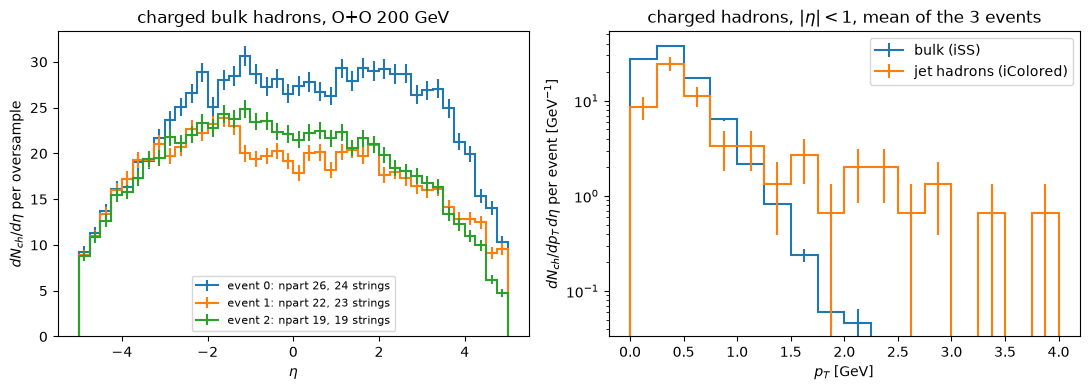

In [11]:
import hist
import matplotlib.pyplot as plt
import mplhep as mh

n_os = ak.num(b, axis=1).to_numpy()                 # oversamples per event (100)
flat = lambda a: ak.to_numpy(ak.flatten(a, axis=None))

h_eta = (hist.Hist.new.Integer(0, len(b), name="event", label="event")
         .Reg(40, -5, 5, name="eta", label=r"$\eta$").Weight())
for e in range(len(b)):
    h_eta.fill(event=e, eta=flat(ch[e].eta), weight=1.0 / n_os[e])

PT = hist.axis.Regular(16, 0, 4, name="pt", label=r"$p_T$ [GeV]")
h_bulk = hist.Hist(PT, storage=hist.storage.Weight())
h_jet = hist.Hist(PT, storage=hist.storage.Weight())
for e in range(len(b)):
    h_bulk.fill(pt=flat(ch[e].pt[abs(ch[e].eta) < 1]), weight=1.0 / (n_os[e] * len(b) * 2.0))
    h_jet.fill(pt=flat(j_ch[e].pt[abs(j_ch[e].eta) < 1]), weight=1.0 / (len(b) * 2.0))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
w_eta = h_eta.axes["eta"].widths[0]
for e in range(len(b)):
    mh.histplot(h_eta[e, :] / w_eta, ax=ax[0], flow="none",
                label=f"event {e}: npart {base.npart[e]}, {base.strings[e]} strings")
ax[0].set(ylabel=r"$dN_{ch}/d\eta$ per oversample", title="charged bulk hadrons, O+O 200 GeV")
ax[0].legend(fontsize=8)
mh.histplot(h_bulk / PT.widths, ax=ax[1], flow="none", label="bulk (iSS)")
mh.histplot(h_jet / PT.widths, ax=ax[1], flow="none", label="jet hadrons (iColored)")
ax[1].set(yscale="log", ylabel=r"$dN_{ch}/dp_T\,d\eta$ per event [GeV$^{-1}$]",
          title=r"charged hadrons, $|\eta| < 1$, mean of the 3 events")
ax[1].legend()
fig.tight_layout()

**What to notice.**

- **Each collision has its own $dN/d\eta$.** The heights differ by up to a factor 1.4, and
  the shapes are lumpy and asymmetric: the strings break the boost invariance along the
  beam, so an event can have more hadrons on one side. Smooth, symmetric distributions appear
  only after averaging over many events (tutorial 05). The 100 oversamples reduce the
  sampling noise, not these event-by-event fluctuations: they all come from the same fluid.
- **The bulk dominates at low $p_T$, the jet at high $p_T$.** The bulk spectrum falls about
  exponentially, as for a thermal source moving with the flow. The jet hadrons fall much
  more slowly and take over above about 1 GeV. Below 1 GeV they are still about half as
  many as the bulk hadrons: iColoredHadronization strings the jet partons together with the
  remnants of the two colliding nucleons, and those strings make soft hadrons too. In a small
  system like O+O, the hard scattering is a sizable part of the whole event.

## 4. Change one setting: the shear viscosity

Now a physics question. How does the friction of the plasma, its shear viscosity, change
what comes out? The relevant quantity is the ratio of the shear viscosity to the entropy
density, $\eta/s$. Strongly coupled theories suggest a lower bound near
$1/4\pi \approx 0.08$, and the QGP is thought to be close to it: it is the most nearly
perfect fluid known.

In this XML, $\eta/s$ depends on the temperature: it is smallest at a *kink* temperature
$T_k$ = 206 MeV and rises linearly on both sides,

$$\frac{\eta}{s}(T) = \left(\frac{\eta}{s}\right)_k + a_{\pm}\,(T - T_k),$$

with $a_\pm = \pm 1.999$ GeV$^{-1}$. We raise $(\eta/s)_k$ from 0.108 to 0.30, which shifts
the whole curve up by 0.19, and change **nothing else**:

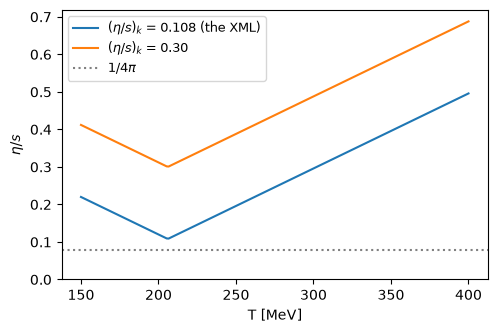

In [12]:
KINK = "Hydro/MUSIC/shear_viscosity_3_at_kink"
tree = ET.parse(BASE_XML)
tree.getroot().find(KINK).text = "0.30"
ETA_XML = OUT / "oo_eta030.xml"
tree.write(ETA_XML)

def eta_over_s(T, xml_path):
    """MUSIC's eta/s(T) for T_dependent_Shear_to_S_ratio 3, from the XML's settings."""
    m = ET.parse(xml_path).getroot().find("Hydro/MUSIC")
    f = lambda tag: float(m.findtext(tag))
    kink, Tk = f("shear_viscosity_3_at_kink"), f("shear_viscosity_3_T_kink_in_GeV")
    slope = np.where(T < Tk, f("shear_viscosity_3_low_T_slope_in_GeV"),
                     f("shear_viscosity_3_high_T_slope_in_GeV"))
    return np.maximum(kink + slope * (T - Tk), 1e-3)

T = np.linspace(0.15, 0.40, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(T * 1000, eta_over_s(T, BASE_XML), label=r"$(\eta/s)_k$ = 0.108 (the XML)")
ax.plot(T * 1000, eta_over_s(T, ETA_XML), label=r"$(\eta/s)_k$ = 0.30")
ax.axhline(1 / (4 * np.pi), color="0.5", ls=":", label=r"$1/4\pi$")
ax.set(xlabel="T [MeV]", ylabel=r"$\eta/s$", ylim=(0, None))
ax.legend(fontsize=9);

What should change? Right after the collision the fluid expands fastest along the beam.
Shear viscosity resists this anisotropic expansion: it lowers the pressure along the beam
and raises it in the transverse plane. More viscous fluid therefore pushes outward harder,
builds up more *radial flow*, and its hadrons come out with larger $p_T$. Viscosity also
produces entropy, so a little more multiplicity is expected.

### Making the comparison fair

With three events, the differences between collisions (up to a factor 1.4 in multiplicity)
are far larger than the effect we look for. So we compare **the same three collisions**,
once with each value. We run the new XML with the same seed. The modules before the hydro
then draw the same random numbers: the same nucleons, strings and hard scattering. MUSIC
itself has no random numbers. Any difference in the fluid then comes from $\eta/s$ alone.

This only works when the change keeps the list of modules. The modules take their random
numbers from engines seeded from the one seed, in the order of the task list. A module added
or removed can change what the others receive, and the events stop matching (exercise 2). We
check that the inputs agree, event by event:

In [13]:
eta = run(ETA_XML, "oo_eta030")
inputs = ["pthat", "npart", "ncoll", "strings", "b", "E sources [GeV]", "iSS seed"]
same = (base[inputs] == eta[inputs]).all()
print("identical in both runs:", same.to_dict())
pd.concat({"eta/s 0.108": base[inputs], "eta/s 0.30": eta[inputs]}, axis=1).round(2)

oo_eta030: 3 events in 20 s; modules: MCGlauber -> PythiaGun (IsrManager, MCGlauberGenString) -> NullPreDynamics -> MUSIC -> JLossManager (JetEnergyLoss) -> HadronizationManager (Hadronization) -> iSS
identical in both runs: {'pthat': True, 'npart': True, 'ncoll': True, 'strings': True, 'b': True, 'E sources [GeV]': True, 'iSS seed': True}


eta/s 0.108                                                        \
            pthat npart ncoll strings     b E sources [GeV]    iSS seed   
event                                                                     
0           20.63    26    24      24  1.36         2419.14  3598293754   
1           26.51    22    20      23  1.89         2035.87  1951155034   
2           20.25    19    17      19  2.85         1728.55  2803241356   

      eta/s 0.30                                                        
           pthat npart ncoll strings     b E sources [GeV]    iSS seed  
event                                                                   
0          20.63    26    24      24  1.36         2419.14  3598293754  
1          26.51    22    20      23  1.89         2035.87  1951155034  
2          20.25    19    17      19  2.85         1728.55  2803241356

The hard scattering, the geometry, the energy MUSIC received from the strings and remnants,
and even the seed iSS sampled with: all identical. The two runs differ in the fluid only.

### The fluid

The freeze-out surface needs no sampling, so its numbers carry no statistical error. The
table compares its lifetime, its number of cells and the mean transverse flow on it, each
cell weighted by the fluid that crosses it. The figure shows, on the left, a cut through
event 0's surface at $y \approx 0$, $\eta_s \approx 0$, colored by the flow $u^x$ (positive
outward on the right, negative on the left), and on the right the distribution of the
transverse flow $u_T$ over the whole surface, for both runs:

,tau_max 0.108,tau_max 0.30,<u_T> 0.108,<u_T> 0.30,<u_T> ratio,cells ratio
event,,,,,,
0,4.293,4.230,0.177,0.194,1.099,1.010
1,3.807,3.841,0.142,0.155,1.096,1.014
2,4.079,4.040,0.199,0.216,1.083,1.006


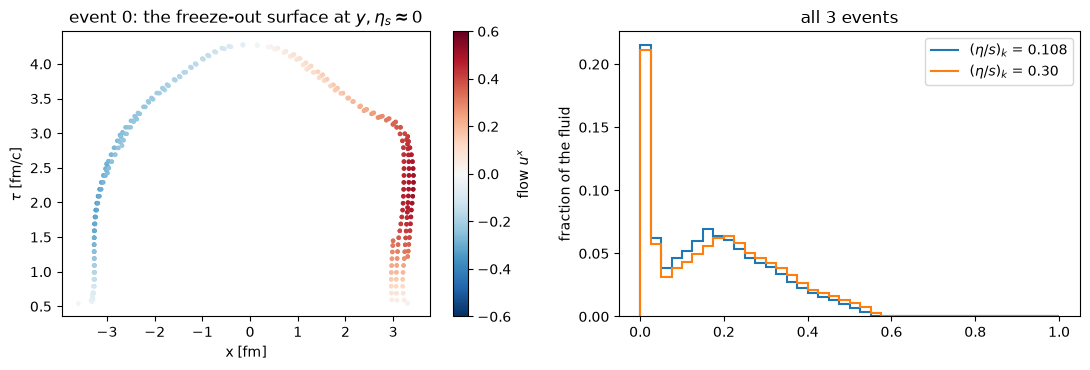

In [14]:
fluid = pd.DataFrame({
    "tau_max 0.108": base.tau_max, "tau_max 0.30": eta.tau_max,
    "<u_T> 0.108": base.flow_uT, "<u_T> 0.30": eta.flow_uT,
    "<u_T> ratio": eta.flow_uT / base.flow_uT,
    "cells ratio": eta.cells / base.cells,
})
display(fluid.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cut = np.load(OUT / "oo_base_surface.npz")["event0"]          # tau, x, u^x of the cells
sc = ax[0].scatter(cut[:, 1], cut[:, 0], c=cut[:, 2], s=5, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
fig.colorbar(sc, ax=ax[0], label=r"flow $u^x$")
ax[0].set(xlabel="x [fm]", ylabel=r"$\tau$ [fm/c]",
          title=r"event 0: the freeze-out surface at $y, \eta_s \approx 0$")
UT = hist.axis.Regular(40, 0, 1, name="uT", label=r"transverse flow $u_T$ on the surface")
for name, label in [("oo_base", r"$(\eta/s)_k$ = 0.108"), ("oo_eta030", r"$(\eta/s)_k$ = 0.30")]:
    with np.load(OUT / f"{name}_surface.npz") as f:
        w = sum(f[f"event{e}_uT"] for e in range(3))           # the 3 events, weighted cells
    mh.histplot(w / w.sum(), UT.edges, ax=ax[1], label=label)
ax[1].set(ylabel="fraction of the fluid", title="all 3 events")
ax[1].legend()
fig.tight_layout()

**What to notice.**

- **The surface has the shape of a fireball.** The fluid's edge stays near $|x| \approx 3.3$
  fm until $\tau \approx 3$ fm/c, then the cold region eats its way in, and the middle
  freezes out last, at $\tau \approx 4.3$ fm/c. The flow points outward everywhere (red on
  the right, blue on the left). On the edge it grows with time, up to $u^x \approx 0.5$;
  toward the middle it falls to zero.
- **The more viscous fluid flows faster.** Its $u_T$ distribution is shifted slightly up, and
  the mean transverse flow on the surface is higher by 8–10 % in every event, with the same
  initial state. The lifetime and the number of cells change by about 1 % only.
- **About a fifth of the fluid has no transverse flow.** That is the spike at $u_T = 0$: fluid
  that is already below 150 MeV when the hydro starts, mostly far forward and backward
  along the beam. It freezes out at once, before any flow builds up.

### The hadrons

The bulk hadrons are sampled, so their averages have errors. With 100 oversamples per
event, the error of the mean $p_T$ is about 1 %:

In [15]:
def bulk_summary(name):
    """dNch/deta at |eta| < 0.5 and mean pT of the charged bulk hadrons at |eta| < 1, per event."""
    a = js.HadronArray.from_h5(OUT / f"{name}_hadrons_bulk_bg.h5").to_awkward(by_unit=True)
    c = a[js.select(a, "charged")]
    rows = []
    for e in range(len(c)):
        n = len(c[e])
        mid = flat(abs(c[e].eta) < 0.5).sum()
        pt = flat(c[e].pt[abs(c[e].eta) < 1])
        rows.append({"dNch/deta": mid / n, "error": np.sqrt(mid) / n,
                     "<pT>": pt.mean(), "<pT> error": pt.std() / np.sqrt(len(pt))})
    return pd.DataFrame(rows)

hb, he = bulk_summary("oo_base"), bulk_summary("oo_eta030")
change = pd.DataFrame({
    "dNch/deta change [%]": 100 * (he["dNch/deta"] / hb["dNch/deta"] - 1),
    "in errors": (he["dNch/deta"] - hb["dNch/deta"]) / np.hypot(he["error"], hb["error"]),
    "<pT> change [%]": 100 * (he["<pT>"] / hb["<pT>"] - 1),
    "in errors ": (he["<pT>"] - hb["<pT>"]) / np.hypot(he["<pT> error"], hb["<pT> error"]),
})
pd.concat({"eta/s 0.108": hb, "eta/s 0.30": he, "0.30 vs 0.108": change}, axis=1).round(3)

eta/s 0.108                          eta/s 0.30                           \
    dNch/deta  error   <pT> <pT> error  dNch/deta  error   <pT> <pT> error   
0       27.46  0.524  0.424      0.004      27.94  0.529  0.444      0.004   
1       19.32  0.440  0.401      0.004      19.94  0.447  0.421      0.004   
2       22.06  0.470  0.420      0.004      22.35  0.473  0.432      0.004   

         0.30 vs 0.108                                       
  dNch/deta change [%] in errors <pT> change [%] in errors   
0                1.748     0.645           4.674      3.763  
1                3.209     0.990           5.071      3.523  
2                1.315     0.435           2.910      2.143

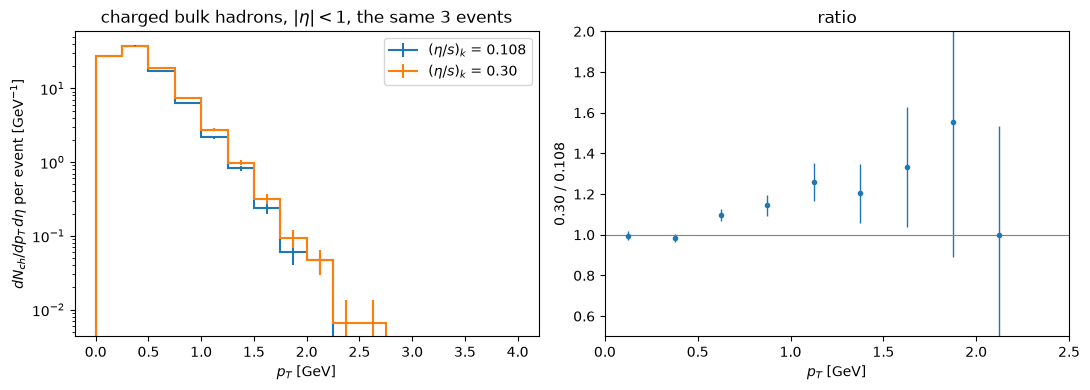

In [16]:
def bulk_pt(name):
    """The charged bulk pT spectrum at |eta| < 1, per event and oversample, of all events."""
    a = js.HadronArray.from_h5(OUT / f"{name}_hadrons_bulk_bg.h5").to_awkward(by_unit=True)
    c = a[js.select(a, "charged")]
    h = hist.Hist(PT, storage=hist.storage.Weight())
    for e in range(len(c)):
        h.fill(pt=flat(c[e].pt[abs(c[e].eta) < 1]), weight=1.0 / (len(c[e]) * len(c) * 2.0))
    return h / PT.widths

s_base, s_eta = bulk_pt("oo_base"), bulk_pt("oo_eta030")
v1, v0 = s_eta.values(), s_base.values()
filled = (v0 > 0) & (v1 > 0)                         # bins with hadrons in both runs
ratio = np.where(filled, v1 / np.where(filled, v0, 1), np.nan)
rel = s_eta.variances() / np.where(filled, v1, 1) ** 2 + s_base.variances() / np.where(filled, v0, 1) ** 2
ratio_err = np.where(filled, ratio * np.sqrt(rel), 0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mh.histplot(s_base, ax=ax[0], flow="none", label=r"$(\eta/s)_k$ = 0.108")
mh.histplot(s_eta, ax=ax[0], flow="none", label=r"$(\eta/s)_k$ = 0.30")
ax[0].set(yscale="log", ylabel=r"$dN_{ch}/dp_T\,d\eta$ per event [GeV$^{-1}$]",
          title=r"charged bulk hadrons, $|\eta| < 1$, the same 3 events")
ax[0].legend()
mh.histplot(ratio, PT.edges, yerr=ratio_err, ax=ax[1], histtype="errorbar", flow="none")
ax[1].axhline(1, color="0.5", lw=0.8)
ax[1].set(xlabel=PT.label, ylabel="0.30 / 0.108", xlim=(0, 2.5), ylim=(0.5, 2), title="ratio")
fig.tight_layout()

**What to notice.**

- **The mean $p_T$ rises in each event,** by 3–5 %, two to four times the error of the
  difference. The multiplicity rises too, but only by 1–3 %, within about one error per
  event.
- **The ratio of the spectra rises with $p_T$.** Below 0.5 GeV the two runs agree; above, the
  more viscous fluid gives more hadrons, up to about 25 % more near 1–1.5 GeV: a flatter,
  *harder* spectrum. This is the stronger radial flow of the surface, now in the hadrons.
  The viscous correction $\delta f$ that iSS adds to the hadrons' momentum distribution
  grows with $\eta/s$ too, and also shapes the spectrum. Above about 1.5 GeV the errors are
  large: there are few bulk hadrons there.

This is how $\eta/s$ is constrained in practice: its effects on spectra and flow are
compared over many events, with everything else fixed, and fitted to data. The famous
signature is the *elliptic flow* $v_2$, which viscosity damps. In central O+O collisions
$v_2$ comes from fluctuations and is small, so measuring it needs many more events than three.

## 5. Without the notebook

The same run, as a script, is the example the notebook started from. In your copy of the
examples (`xscape-examples` makes one; in a checkout it is
`contribs/PyJetscape/example/pythonic/`):

```bash
python oo_workflow.py --xml <this folder>/out/02_first_events/oo_eta030.xml --outdir out_eta030
python oo_workflow.py --events 10 --seed 3 --outdir out_oo_s3
```

It writes the same two kinds of hadron files. And X-SCAPE runs a user XML without Python at all, with
its own executable. On a Mac, the wheel's `xscape-run` copies both XMLs into a run directory,
makes their paths absolute, links the tables and checks the XML before it starts:

```bash
xscape-run -w ~/xscape/runs/oo -u <this folder>/out/02_first_events/oo_base.xml
```

Then X-SCAPE's own writers decide what is stored, and this XML switches them all off: set,
for example, `<JetScapeWriterFinalStateHadronsAscii> on </JetScapeWriterFinalStateHadronsAscii>`
in a copy. In a source build the script behind `xscape-run` is
`X-SCAPE/examples/run_in_workdir.sh`. Details:
[Your first event](https://jhputschke.github.io/js-contrib/run/first-event/#the-same-xml-without-python-xscape-run).

### Check your result

Your numbers come from your own run of X-SCAPE. With the same build they are the ones shown,
bit for bit. Another GPU, or MUSIC on the CPU, changes them slightly, and another build of
PYTHIA or 3dMCGlauber can give other collisions altogether. The check allows for that: the
comparison must be fair and show the same physics everywhere, and the numbers must match
where the collisions do:

In [17]:
import json
exp = json.load(open("expected/02_first_events.json"))
# on any setup: a fair comparison, and the physics
assert same.all(), "the two runs must have the same inputs"
assert (eta.flow_uT > base.flow_uT).all() and (he["<pT>"] > hb["<pT>"]).all()
# the same collisions as shown here (seed 7), unless your build of PYTHIA or 3dMCGlauber differs
if np.allclose(base.pthat, exp["pthat"], rtol=1e-6):
    assert (base.npart.tolist(), base.ncoll.tolist()) == (exp["npart"], exp["ncoll"])
    np.testing.assert_allclose(base.cells, exp["cells"], rtol=0.02)
    np.testing.assert_allclose(hb["dNch/deta"], exp["dNch_deta"], rtol=0.1)
    np.testing.assert_allclose(hb["<pT>"], exp["mean_pt"], rtol=0.03)
else:
    print("Your collisions differ from the ones shown (another build): only the physics was checked.")
print("All checks pass.")

All checks pass.


## Exercises

1. **Another setting.** Switch the bulk viscosity off (`bulk_viscosity_3_max` 0), or lower
   $(\eta/s)_k$ to 0.08, and compare with the first run the same way. Which way does the mean
   $p_T$ move?
2. **Removing a module.** Delete the `<Lbt>` element from a copy of `oo_base.xml` (so that
   only MATTER acts on the jets) and run it. Compare the inputs table with the first run:
   which events are still the same collisions? How would you switch LBT off and keep the
   events? (Look at `<in_vac>` in the XML.)
3. **The jets.** In `oo_base_partons.npz` and `oo_eta030_partons.npz`, compare the recoils and holes of each
   event. Does the jet lose more energy in the more viscous fluid? Think about which medium
   property the energy loss reads (temperature, flow) before you look.
4. **More events.** Run 10 events with each $\eta/s$ (edit `nEvents`, or use
   `oo_workflow.py`) and compare the mean $p_T$ averaged over events, with the
   event-to-event spread as its error.

## Next steps

- The production scripts, seeds and campaigns, and a Au+Au job with its hadronization: tutorial 03.
- The files a production writes and where they record their settings: tutorial 04.
- Spectra and $dN/d\eta$ over many events, oversamples and weights: tutorial 05.
- Every method of the interface: [The Pythonic interface](https://jhputschke.github.io/js-contrib/python/pythonic/).
- Every stage and its settings: [The physics](https://jhputschke.github.io/js-contrib/about/physics/); the O+O production: [O+O with ISR](https://jhputschke.github.io/js-contrib/run/oo-isr/).